# Why a qubit needs a dilution refrigerator, and how it is read out

A mini-project tied to two Fall 2026 courses. Each section is something you study anyway:

| Section | Course | Concept |
|---|---|---|
| 1–2 | **PHYS 106** | Boltzmann factor, Bose-Einstein photons, energy levels |
| 3 | **EEE 117 / 117L** | Series RLC transfer function, ω₀, Q, bandwidth, Bode plots |
| 4 | **EEE 117** + PHYS 106 | A resonator whose frequency depends on the qubit state gives a binary readout |
| 5 | both | Attenuators as noise dividers: why the fridge's coax has an attenuator at every stage |

**Teaching pattern:** quantity → equation → isolated variable → units → meaning.
Parameters marked *illustrative* are typical orders of magnitude, not a specific device.
Module: `dgs/cryo_readout.py` (tests: `tests/test_cryo_readout.py`).

In [1]:
import sys, math
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))

import sympy as sp
sp.init_printing(use_unicode=True)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from dgs import cryo_readout as R
pd.set_option("display.width", 200)
STAGES = {"room 300 K": 300.0, "liquid N2 77 K": 77.0, "4 K plate": 4.0, "still ~1 K": 1.0,
          "cold plate 100 mK": 0.1, "mixing chamber 15 mK": 0.015}

## 1. PHYS 106: the Boltzmann factor says how cold

**Quantity:** P₁, the probability the qubit is found in its upper level before we touch it.
**Equation:** for two levels separated by hf, the Boltzmann weights are 1 and e^(−hf/k_BT), so

$$P_1 = \frac{e^{-hf/k_BT}}{1 + e^{-hf/k_BT}} = \frac{1}{1 + e^{hf/k_BT}}.$$

**Isolated:** T = (hf/k_B) / ln((1−P₁)/P₁). **Units:** hf/k_B is a temperature, in K.
**Meaning:** the qubit only starts reliably in |0⟩ when k_BT ≪ hf. For 5 GHz,
hf/k_B = 0.24 K, so we need T of tens of millikelvin.

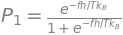

same expression? True


f = 4 GHz:  hf/k_B =  192.0 mK
f = 5 GHz:  hf/k_B =  240.0 mK
f = 6 GHz:  hf/k_B =  288.0 mK
f = 8 GHz:  hf/k_B =  383.9 mK


In [2]:
h, f, kB, T, P1 = sp.symbols("h f k_B T P_1", positive=True)
x = h * f / (kB * T)
P1_expr = sp.exp(-x) / (1 + sp.exp(-x))
display(sp.Eq(P1, P1_expr), sp.Eq(P1, sp.simplify(1 / (1 + sp.exp(x)))))
print("same expression?", sp.simplify(P1_expr - 1 / (1 + sp.exp(x))) == 0)
T_iso = sp.solve(sp.Eq(P1, 1 / (1 + sp.exp(x))), T)
display(sp.Eq(T, T_iso[0]))

for fq in (4e9, 5e9, 6e9, 8e9):
    print(f"f = {fq / 1e9:.0f} GHz:  hf/k_B = {R.quantum_temperature(fq) * 1e3:6.1f} mK")

,stage,T (K),P1 at 5 GHz,thermal photons n_th at 5 GHz
0,room 300 K,300.000,4.998000e-01,1.249697e+03
1,liquid N2 77 K,77.000,4.992209e-01,3.203842e+02
2,4 K plate,4.000,4.850069e-01,1.617429e+01
3,still ~1 K,1.000,4.402957e-01,3.687302e+00
4,cold plate 100 mK,0.100,8.320156e-02,9.981031e-02
5,mixing chamber 15 mK,0.015,1.128195e-07,1.128195e-07


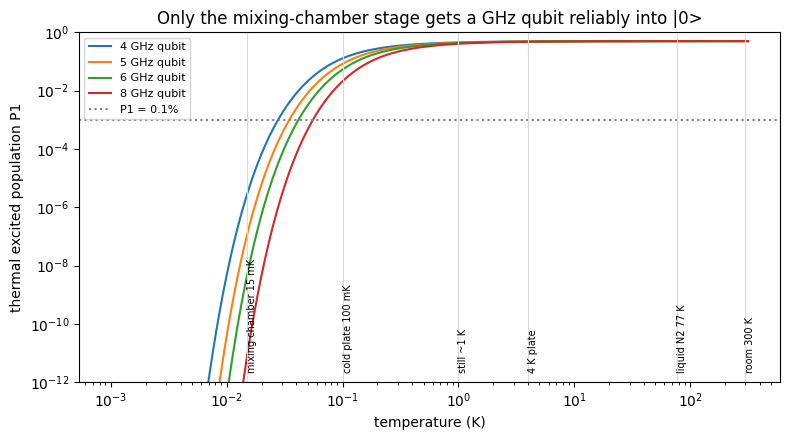

In [3]:
rows = [(name, Tk, R.excited_population(5e9, Tk), R.mean_photon_number(5e9, Tk)) for name, Tk in STAGES.items()]
display(pd.DataFrame(rows, columns=["stage", "T (K)", "P1 at 5 GHz", "thermal photons n_th at 5 GHz"]))

Ts = np.logspace(-3, 2.5, 400)
fig, ax = plt.subplots(figsize=(8, 4.5))
for fq in (4e9, 5e9, 6e9, 8e9):
    ax.loglog(Ts, R.excited_population(fq, Ts), label=f"{fq / 1e9:.0f} GHz qubit")
ax.axhline(1e-3, color="0.5", ls=":", label="P1 = 0.1%")
for name, Tk in STAGES.items():
    ax.axvline(Tk, color="0.85", lw=0.8); ax.text(Tk, 2e-12, name, rotation=90, fontsize=7, va="bottom")
ax.set_ylim(1e-12, 1); ax.set_xlabel("temperature (K)"); ax.set_ylabel("thermal excited population P1")
ax.set_title("Only the mixing-chamber stage gets a GHz qubit reliably into |0>")
ax.legend(fontsize=8, loc="upper left"); plt.tight_layout(); plt.show()

## 2. PHYS 106: photons, effective temperature, and a third level

The readout resonator is a harmonic oscillator, a ladder of evenly spaced levels (Knight 40.8).
Its mean thermal photon number follows Bose-Einstein:

$$\bar n_{th} = \frac{1}{e^{hf/k_BT} - 1}, \qquad \frac{\bar n}{\bar n + 1} = e^{-hf/k_BT} = \frac{P_1}{P_0}.$$

Running this backwards gives the **effective temperature**. Measure P₁ and solve for T. Real
qubits are commonly found "hotter" than the fridge plate they sit on, because stray radiation
and noise from the lines heat them. The attenuator chain in §5 is about that heating.

In [4]:
n = sp.Symbol("n", positive=True)
nbar = 1 / (sp.exp(x) - 1)
display(sp.Eq(sp.Symbol("n_th"), nbar))
print("n/(n+1) == exp(-hf/kT)?", sp.simplify(nbar / (nbar + 1) - sp.exp(-x)) == 0)
print("high-T limit, series in 1/T:", sp.series(nbar.subs(T, 1 / sp.Symbol("u", positive=True)), sp.Symbol("u", positive=True), 0, 2))

for p in (1e-3, 1e-2, 5e-2):
    print(f"measured P1 = {p:5.3f} at 5 GHz  ->  T_eff = {R.effective_temperature(5e9, p) * 1e3:5.1f} mK")

alpha = -250e6   # illustrative transmon anharmonicity
pop = pd.DataFrame({T_: R.level_populations(5e9, T_, 3, alpha) for T_ in (0.015, 0.05, 0.1, 4.0)},
                   index=["|0>", "|1>", "|2>"])
pop.columns = [f"T = {c * 1e3:g} mK" for c in pop.columns]
display(pop)

n/(n+1) == exp(-hf/kT)? True
high-T limit, series in 1/T: k_B/(f*h*u) - 1/2 + f*h*u/(12*k_B) + O(u**2)
measured P1 = 0.001 at 5 GHz  ->  T_eff =  34.7 mK
measured P1 = 0.010 at 5 GHz  ->  T_eff =  52.2 mK
measured P1 = 0.050 at 5 GHz  ->  T_eff =  81.5 mK


,T = 15 mK,T = 50 mK,T = 100 mK,T = 4000 mK
|0>,9.999999e-01,0.991746,0.909059,0.353185
|1>,1.128195e-07,0.008168,0.082499,0.332621
|2>,2.832363e-14,0.000086,0.008441,0.314194


## 3. EEE 117: the readout resonator is an RLC circuit

**Quantity:** H(s) = V_R/V_in for a series RLC with the output taken across R.
**Equation:** voltage divider with impedances R, sL, 1/(sC).
**Isolated:** ω₀ = 1/√(LC), Q = ω₀L/R = (1/R)√(L/C), bandwidth Δω = ω₀/Q = R/L.
**Units:** √(L/C) is in ohms, so Q is dimensionless. **Meaning:** a high-Q resonator only
responds in a narrow band around f₀. That narrow band is what lets a tiny frequency shift (§4) be seen.

In [5]:
s, Rr, L, C = sp.symbols("s R L C", positive=True)
Hs = sp.simplify(Rr / (Rr + s * L + 1 / (s * C)))
display(sp.Eq(sp.Symbol("H(s)"), Hs))
num, den = sp.fraction(sp.together(Hs))
den_monic = sp.expand(den / sp.Poly(den, s).LC())
display(sp.Eq(sp.Symbol("denominator"), den_monic))
w0, Q = sp.symbols("omega_0 Q", positive=True)
print("compare with s^2 + (omega0/Q) s + omega0^2:")
sol = sp.solve([sp.Eq(w0**2, 1 / (L * C)), sp.Eq(w0 / Q, Rr / L)], [w0, Q], dict=True)[0]
display(sp.Eq(w0, sol[w0]), sp.Eq(Q, sp.simplify(sol[Q])))

compare with s^2 + (omega0/Q) s + omega0^2:


bench: f0 = 15.92 kHz, Q = 10.0, bandwidth = 1592 Hz
chip : f0 = 7.00 GHz, Q = 10.0, C = 516.9 fF, R = 4.40 ohm


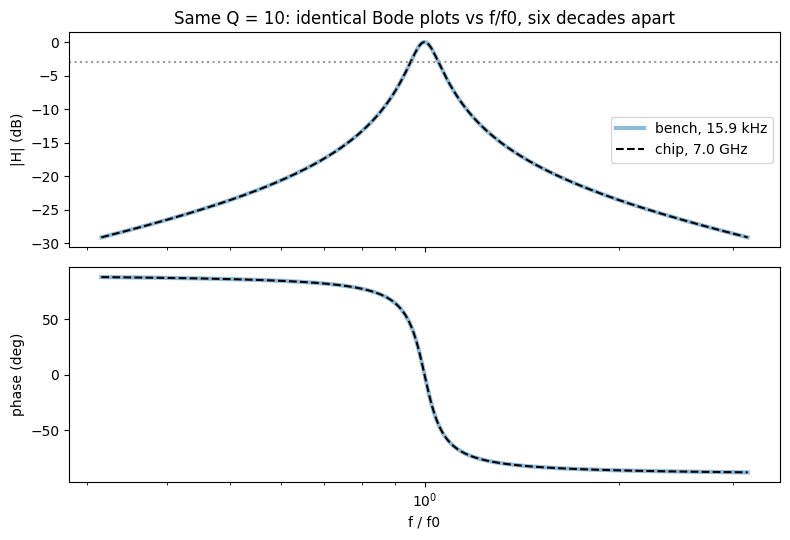

max |difference| between the two curves: 5.467496156816292e-15


In [6]:
bench = dict(R=10.0, L=1e-3, C=1e-7)                       # EEE 117L-style parts
f_b, Q_b = R.rlc_resonance(bench["L"], bench["C"]), R.series_rlc_q(**bench)
L_chip = 1e-9                                              # illustrative on-chip resonator at 7 GHz
C_chip = 1 / ((2 * math.pi * 7e9)**2 * L_chip)
R_chip = math.sqrt(L_chip / C_chip) / Q_b                  # chosen to give the same Q
f_c = R.rlc_resonance(L_chip, C_chip)
print(f"bench: f0 = {f_b / 1e3:.2f} kHz, Q = {Q_b:.1f}, bandwidth = {f_b / Q_b:.0f} Hz")
print(f"chip : f0 = {f_c / 1e9:.2f} GHz, Q = {R.series_rlc_q(R_chip, L_chip, C_chip):.1f}, C = {C_chip * 1e15:.1f} fF, R = {R_chip:.2f} ohm")

u = np.logspace(-0.5, 0.5, 800)
Hb = R.series_rlc_bandpass(u * f_b, **bench)
Hc = R.series_rlc_bandpass(u * f_c, R_chip, L_chip, C_chip)
fig, (a1, a2) = plt.subplots(2, 1, figsize=(8, 5.5), sharex=True)
a1.semilogx(u, 20 * np.log10(np.abs(Hb)), lw=3, alpha=0.5, label=f"bench, {f_b / 1e3:.1f} kHz")
a1.semilogx(u, 20 * np.log10(np.abs(Hc)), "k--", label=f"chip, {f_c / 1e9:.1f} GHz")
a1.axhline(-3, color="0.6", ls=":"); a1.set_ylabel("|H| (dB)"); a1.legend()
a1.set_title(f"Same Q = {Q_b:.0f}: identical Bode plots vs f/f0, six decades apart")
a2.semilogx(u, np.degrees(np.angle(Hb)), lw=3, alpha=0.5); a2.semilogx(u, np.degrees(np.angle(Hc)), "k--")
a2.set_xlabel("f / f0"); a2.set_ylabel("phase (deg)")
plt.tight_layout(); plt.show()
print("max |difference| between the two curves:", np.abs(Hb - Hc).max())

## 4. From an analog dip to a binary bit: dispersive readout

The readout resonator hangs off a feedline ("hanger"), so it shows up as a **dip** in
transmission S21:

$$S_{21}(f) = 1 - \frac{Q/Q_c}{1 + 2jQ\,(f - f_0)/f_0}, \qquad \frac1Q = \frac1{Q_i} + \frac1{Q_c}.$$

Coupling to the qubit pulls the resonator to f₀ − χ when the qubit is in |0⟩ and f₀ + χ in
|1⟩. Probe at the midpoint. The two states give complex S21 values on opposite sides of the IQ
plane. Add amplifier noise, draw a threshold line, and every shot becomes a 0 or a 1.
**Illustrative parameters:** f₀ = 7 GHz, Q_i = 10⁵, Q_c = 2×10⁴, χ/2π = 0.5 MHz.

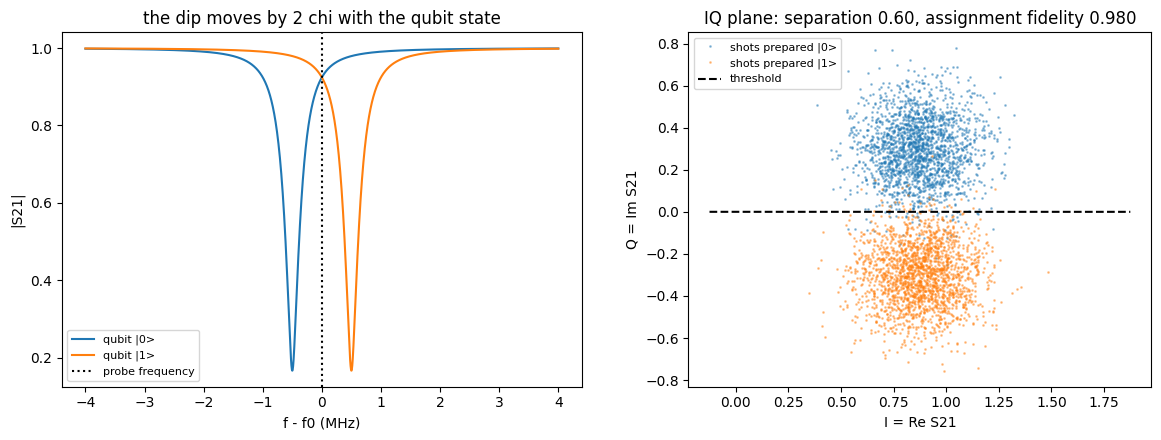

linewidth f0/Q = 420 kHz vs 2 chi = 1000 kHz


In [7]:
f0, Qi, Qc, chi = 7e9, 1e5, 2e4, 0.5e6
ff = f0 + np.linspace(-4e6, 4e6, 2000)
S0 = R.hanger_s21(ff, f0 - chi, Qi, Qc); S1 = R.hanger_s21(ff, f0 + chi, Qi, Qc)
s0, s1, sep = R.dispersive_readout(f0, f0, chi, Qi, Qc)

rng = np.random.default_rng(7)
sigma, shots = 0.15, 2000                                 # illustrative noise per shot
iq0 = s0 + sigma * (rng.standard_normal(shots) + 1j * rng.standard_normal(shots))
iq1 = s1 + sigma * (rng.standard_normal(shots) + 1j * rng.standard_normal(shots))
axis = (s1 - s0) / abs(s1 - s0); mid = (s0 + s1) / 2
bit = lambda z: (((z - mid) * np.conj(axis)).real > 0).astype(int)
fid = 1 - 0.5 * (bit(iq0).mean() + (1 - bit(iq1)).mean())

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.5))
a1.plot((ff - f0) / 1e6, np.abs(S0), label="qubit |0>"); a1.plot((ff - f0) / 1e6, np.abs(S1), label="qubit |1>")
a1.axvline(0, color="k", ls=":", label="probe frequency"); a1.set_xlabel("f - f0 (MHz)"); a1.set_ylabel("|S21|")
a1.legend(fontsize=8); a1.set_title("the dip moves by 2 chi with the qubit state")
a2.plot(iq0.real, iq0.imag, ".", ms=2, alpha=0.4, label="shots prepared |0>")
a2.plot(iq1.real, iq1.imag, ".", ms=2, alpha=0.4, label="shots prepared |1>")
perp = 1j * axis
a2.plot([(mid - perp).real, (mid + perp).real], [(mid - perp).imag, (mid + perp).imag], "k--", label="threshold")
a2.set_aspect("equal"); a2.set_xlabel("I = Re S21"); a2.set_ylabel("Q = Im S21"); a2.legend(fontsize=8)
a2.set_title(f"IQ plane: separation {sep:.2f}, assignment fidelity {fid:.3f}")
plt.tight_layout(); plt.show()
print(f"linewidth f0/Q = {f0 * (1 / Qi + 1 / Qc) / 1e3:.0f} kHz vs 2 chi = {2 * chi / 1e3:.0f} kHz")

## 5. Both courses: the attenuator chain

A coax line from room temperature carries thermal noise: n̄_th(300 K) ≈ 1250 photons per mode
at 5 GHz. An attenuator is a resistive divider (EEE 117). At temperature T_stage, it passes 1/A
of the incoming noise and adds its own thermal noise (PHYS 106):

$$\bar n_{out} = \frac{\bar n_{in}}{A} + \left(1 - \frac1A\right)\bar n_{th}(T_{stage}).$$

This is why the drive lines get attenuation **at several cold stages**. Without the cold
attenuators, the last stage would still be fed with the noise of whatever sits above it.
*Illustrative chain:* 20 dB at 4 K, 20 dB at 100 mK, 20 dB at 15 mK.

,point,thermal photons at 5 GHz
0,300 K source,1249.697214
1,after 20 dB @ 4 K,28.509523
2,after 20 dB @ 100 mK,0.383907
3,after 20 dB @ 15 mK,0.003839


all 60 dB at 4 K instead: n = 16.18 photons  (the 4 K attenuator re-radiates 4 K noise)
mixing chamber alone would give n_th(15 mK) = 1.1e-07; the residual 3.8e-03 is mostly leftover 100 mK noise -> more cold attenuation helps


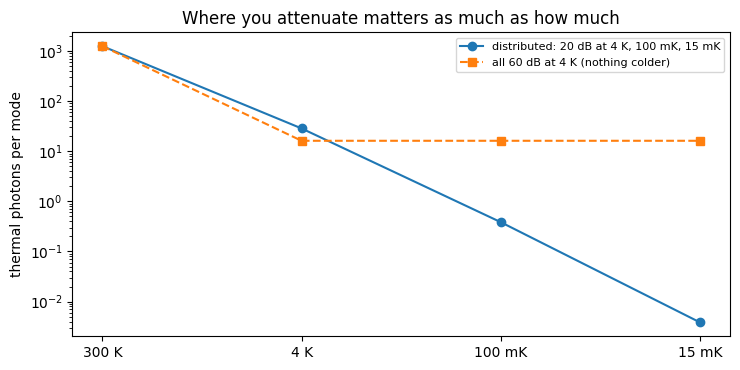

In [8]:
chain = [(20, 4.0), (20, 0.1), (20, 0.015)]
n_chain = R.attenuator_chain(5e9, 300.0, chain)
only_4K = R.attenuator_chain(5e9, 300.0, [(60, 4.0)])
labels = ["300 K source"] + [f"after {dB} dB @ {T * 1e3:g} mK" if T < 1 else f"after {dB} dB @ {T:g} K" for dB, T in chain]
display(pd.DataFrame({"point": labels, "thermal photons at 5 GHz": n_chain}))
print(f"all 60 dB at 4 K instead: n = {only_4K[-1]:.2f} photons  (the 4 K attenuator re-radiates 4 K noise)")
print(f"mixing chamber alone would give n_th(15 mK) = {R.mean_photon_number(5e9, 0.015):.1e}; "
      f"the residual {n_chain[-1]:.1e} is mostly leftover 100 mK noise -> more cold attenuation helps")

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.semilogy(range(len(n_chain)), n_chain, "o-", label="distributed: 20 dB at 4 K, 100 mK, 15 mK")
ax.semilogy(range(4), [only_4K[0]] + [only_4K[-1]] * 3, "s--", label="all 60 dB at 4 K (nothing colder)")
ax.set_xticks(range(len(n_chain))); ax.set_xticklabels(["300 K", "4 K", "100 mK", "15 mK"])
ax.set_ylabel("thermal photons per mode"); ax.legend(fontsize=8)
ax.set_title("Where you attenuate matters as much as how much")
plt.tight_layout(); plt.show()

## Practice (my own problems)

1. **PHYS 106:** a 6 GHz qubit has P₁ = 0.5%. What is its effective temperature?
2. **PHYS 106:** at what temperature does a 5 GHz mode hold one thermal photon on average?
3. **EEE 117:** a bench series RLC has L = 10 mH, C = 10 nF, R = 20 Ω. Find f₀, Q, and the bandwidth.
4. **EEE 117:** a 7 GHz resonator must have a 1 MHz bandwidth. What Q is that?
5. **Both:** a single 30 dB attenuator at 4 K follows a 300 K source. How many photons remain at 5 GHz?

In [9]:
print(f"1. T_eff = {R.effective_temperature(6e9, 0.005) * 1e3:.1f} mK")
T1 = R.quantum_temperature(5e9) / math.log(2)
print(f"2. n = 1 when exp(hf/kT) = 2 -> T = (hf/k_B)/ln 2 = {T1 * 1e3:.0f} mK;  check n = {R.mean_photon_number(5e9, T1):.3f}")
f3 = R.rlc_resonance(10e-3, 10e-9); Q3 = R.series_rlc_q(20, 10e-3, 10e-9)
print(f"3. f0 = {f3:.0f} Hz, Q = {Q3:.1f}, bandwidth = {f3 / Q3:.0f} Hz (= R / 2 pi L = {20 / (2 * math.pi * 10e-3):.0f} Hz)")
print(f"4. Q = f0 / bandwidth = {7e9 / 1e6:.0f}")
print(f"5. n = {R.attenuator_chain(5e9, 300.0, [(30, 4.0)])[-1]:.2f} photons (floor is n_th(4 K) = {R.mean_photon_number(5e9, 4.0):.1f})")

1. T_eff = 54.4 mK
2. n = 1 when exp(hf/kT) = 2 -> T = (hf/k_B)/ln 2 = 346 mK;  check n = 1.000
3. f0 = 15915 Hz, Q = 50.0, bandwidth = 318 Hz (= R / 2 pi L = 318 Hz)
4. Q = f0 / bandwidth = 7000
5. n = 17.41 photons (floor is n_th(4 K) = 16.2)


## Checklist

- [ ] k_BT vs hf: P₁ = 1/(1 + e^(hf/k_BT)). For 5 GHz, hf/k_B = 0.24 K, so a dilution fridge (~10–20 mK) is required.
- [ ] Resonator photons follow Bose-Einstein. n̄/(n̄+1) equals the Boltzmann ratio P₁/P₀.
- [ ] Series RLC: ω₀ = 1/√(LC), Q = (1/R)√(L/C), bandwidth = R/(2πL). The curve depends only on f/f₀ and Q.
- [ ] Hanger dip depth = Q_c/(Q_i + Q_c). A qubit-state shift of ±χ, read through the IQ plane and a threshold, gives one bit per shot.
- [ ] Attenuators are noise dividers at a temperature. Spread them over the cold stages.
- [ ] Next course tie-in (ENGR 140): buy a fridge vs. rent cloud qubit time, as an NPV problem.